# Question 8 — Adapter la conduite à chaque terroir
Je repars des 4 terroirs identifiés à la question 7 (parcelles_terroirs.csv) pour analyser les pratiques de conduite et voir comment optimiser le rendement et la qualité (premium) sur chaque groupe. Je commence par charger les données et vérifier les colonnes disponibles ainsi que les éventuelles valeurs manquantes.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/parcelles_terroirs.csv")
print("Dimensions :", df.shape)
print("Colonnes :", list(df.columns))

print("\nValeurs manquantes par colonne :")
display(df.isna().sum()[df.isna().sum() > 0])

display(df.head())

Dimensions : (220, 20)
Colonnes : ['parcelle_id', 'surface_ha', 'cepage', 'age_vignes_ans', 'type_sol', 'altitude_m', 'pente_pct', 'exposition', 'densite_pieds_ha', 'pluviometrie_mm', 'azote_apporte_g_ha', 'traitements_an', 'est_ouest_km', 'nord_sud_km', 'rendement_kg_ha', 'classement_recolte', 'rendement_nul_a_verifier', 'terroir', 'silhouette_parcelle', 'nom_terroir']

Valeurs manquantes par colonne :


exposition         8
pluviometrie_mm    8
dtype: int64

,parcelle_id,surface_ha,cepage,age_vignes_ans,type_sol,altitude_m,pente_pct,exposition,densite_pieds_ha,pluviometrie_mm,azote_apporte_g_ha,traitements_an,est_ouest_km,nord_sud_km,rendement_kg_ha,classement_recolte,rendement_nul_a_verifier,terroir,silhouette_parcelle,nom_terroir
0,P150,0.70,syrah,31.0,argilo-calcaire,242.0,3.6,sud,3778.0,668.0,29396.0,2,3.89,7.34,7149.0,standard,False,0,0.300704,Hauts plateaux secs
1,P75,0.73,syrah,22.0,sableux,235.0,9.0,nord,3903.0,594.0,47287.0,3,8.02,2.68,6580.0,premium,False,0,0.289775,Hauts plateaux secs
2,P105,1.73,syrah,17.0,limoneux,243.0,4.5,sud-est,4052.0,722.0,9632.0,7,2.15,3.35,5825.0,premium,False,3,0.059014,Terres humides
3,P32,1.31,grenache,5.0,limoneux,276.0,11.8,sud-est,4212.0,700.0,39640.0,7,4.97,6.99,6887.0,premium,False,0,0.090515,Hauts plateaux secs
4,P73,0.66,syrah,2.0,caillouteux,268.0,4.2,sud-est,5186.0,789.0,24436.0,3,8.60,1.21,7300.0,standard,False,3,0.177544,Terres humides


Je commence par écarter les 3 parcelles à rendement nul (rendement_nul_a_verifier) pour ne pas fausser l'analyse de la récolte. J'observe ensuite les 7 nombres essentiels et les boîtes à moustaches des 3 variables de conduite (densite_pieds_ha, azote_apporte_g_ha, traitements_an) ainsi que la répartition des classements de récolte.

Parcelles analysées : 217 sur 220

Répartition globale de classement_recolte :


classement_recolte
premium     137
standard     80
Name: count, dtype: int64


Indicateurs des variables de conduite et du rendement :


,densite_pieds_ha,azote_apporte_g_ha,traitements_an,rendement_kg_ha
count,217.0,217.0,217.0,217.0
mean,4200.5,37712.4,6.2,6704.5
std,482.2,10973.2,2.4,973.8
min,2963.0,9632.0,1.0,4483.0
25%,3869.0,29767.0,5.0,6049.0
50%,4219.0,38182.0,6.0,6770.0
75%,4588.0,45555.0,8.0,7368.0
max,5302.0,74673.0,15.0,9438.0


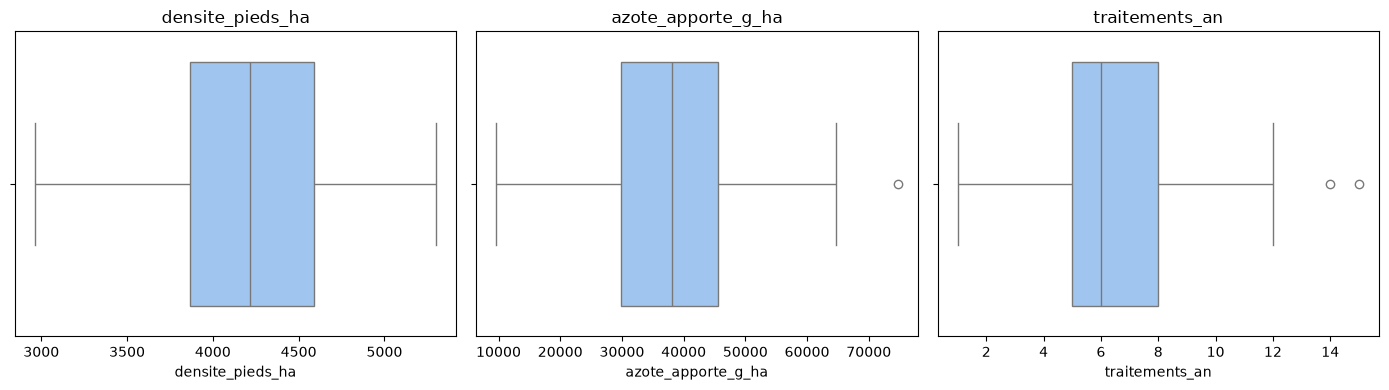

In [3]:
df_q8 = df[~df["rendement_nul_a_verifier"]].copy()
print("Parcelles analysées :", len(df_q8), "sur", len(df))

print("\nRépartition globale de classement_recolte :")
display(df_q8["classement_recolte"].value_counts(dropna=False))

cols_conduite = ["densite_pieds_ha", "azote_apporte_g_ha", "traitements_an"]
print("\nIndicateurs des variables de conduite et du rendement :")
display(df_q8[cols_conduite + ["rendement_kg_ha"]].describe().round(1))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, cols_conduite):
    sns.boxplot(x=df_q8[col], ax=ax, color="#93c5fd")
    ax.set_title(col)
plt.tight_layout()
plt.show()

Maintenant je regarde comment la densité, l'azote et les traitements varient entre les parcelles premium et les autres dans chaque terroir puis je vérifie leur corrélation avec le rendement.
Cela permet de voir si une conduite marche partout ou si chaque terroir a besoin de ses propres réglages.

In [4]:
print("Conduite moyenne par terroir (toutes parcelles valides) :")
display(df_q8.groupby("nom_terroir")[cols_conduite].mean().round(1))

print("Conduite moyenne par terroir et classement :")
comp = df_q8.groupby(["nom_terroir", "classement_recolte"]).agg(
    nb_parcelles=("parcelle_id", "count"),
    densite_moy=("densite_pieds_ha", "mean"),
    azote_moy=("azote_apporte_g_ha", "mean"),
    traitements_moy=("traitements_an", "mean"),
    rendement_moy=("rendement_kg_ha", "mean")
).round(1)
display(comp)

print("Corrélation de la conduite avec le rendement (global) :")
display(df_q8[cols_conduite + ["rendement_kg_ha"]].corr()[["rendement_kg_ha"]].round(2))

print("Corrélation de la conduite avec le rendement PAR TERROIR :")
corr_terroir = {}
for t, groupe in df_q8.groupby("nom_terroir"):
    corr_terroir[t] = groupe[cols_conduite].corrwith(groupe["rendement_kg_ha"]).round(2)
display(pd.DataFrame(corr_terroir).T)

Conduite moyenne par terroir (toutes parcelles valides) :


,densite_pieds_ha,azote_apporte_g_ha,traitements_an
nom_terroir,,,
Basses plaines sèches,4167.6,37707.5,6.0
Coteaux pentus,4185.5,38058.5,6.7
Hauts plateaux secs,4227.7,38208.6,6.1
Terres humides,4211.9,36884.1,6.2


Conduite moyenne par terroir et classement :


nb_parcelles  densite_moy  \
nom_terroir           classement_recolte                              
Basses plaines sèches premium                       34       4227.8   
                      standard                      25       4085.7   
Coteaux pentus        premium                       29       4176.3   
                      standard                       6       4230.2   
Hauts plateaux secs   premium                       45       4235.2   
                      standard                      23       4213.1   
Terres humides        premium                       29       4240.3   
                      standard                      26       4180.1   

                                          azote_moy  traitements_moy  \
nom_terroir           classement_recolte                               
Basses plaines sèches premium               31681.7              6.3   
                      standard              45902.7              5.6   
Coteaux pentus        premium               35383.2              6.7   
                      standard              50988.8              7.0   
Hauts plateaux secs   premium               34512.3              6.2   
                      standard              45440.4              5.9   
Terres humides        premium               31810.4              6.3   
                      standard              42543.2              6.2   

                                          rendement_moy  
nom_terroir           classement_recolte                 
Basses plaines sèches premium                    6184.1  
                      standard                   7670.3  
Coteaux pentus        premium                    5742.4  
                      standard                   7557.5  
Hauts plateaux secs   premium                    6149.6  
                      standard                   7703.9  
Terres humides        premium                    6386.9  
                      standard                   7763.2

Corrélation de la conduite avec le rendement (global) :


,rendement_kg_ha
densite_pieds_ha,0.07
azote_apporte_g_ha,0.58
traitements_an,-0.01
rendement_kg_ha,1.00


Corrélation de la conduite avec le rendement PAR TERROIR :


,densite_pieds_ha,azote_apporte_g_ha,traitements_an
Basses plaines sèches,0.18,0.63,-0.11
Coteaux pentus,0.24,0.78,0.13
Hauts plateaux secs,-0.04,0.52,0.10
Terres humides,-0.02,0.65,-0.03


H1: Je pense que l'azote est le levier principal entre standard et premium, avec un dosage propre à chaque terroir car sa corrélation au rendement atteint +0,52 à +0,78, et les parcelles standard en reçoivent 10 700 à 15 600 g/ha de plus que les premium (31 810 g/ha en Terres humides contre 35 383 en Coteaux pentus) pour le prouver je découpe l'azote en tranches par terroir pour repérer le seuil à ne pas dépasser.

H2: Je pense qu'il existe un seuil direct entre fort rendement et qualité premium puisque dans tous les terroirs, les premium produisent en moyenne 5 742 à 6 387 kg/ha, contre 7 558 à 7 763 kg/ha pour les standard. je vais examiner la distribution exacte des rendements entre les deux classements.   

H3: Je pense que la densité et les traitements jouent peu, ou cachent une zone optimale non linéaire car leurs corrélations globales au rendement sont quasi nulles (+0,07 et -0,01) et leurs moyennes varient peu entre premium et standard donc j'observe le taux de premium et le rendement par tranches dans chaque terroir.   

Rendement min / médiane / max selon le classement


,count,min,median,max
classement_recolte,,,,
premium,137,4483.0,6241.0,6997.0
standard,80,7003.0,7578.0,9438.0


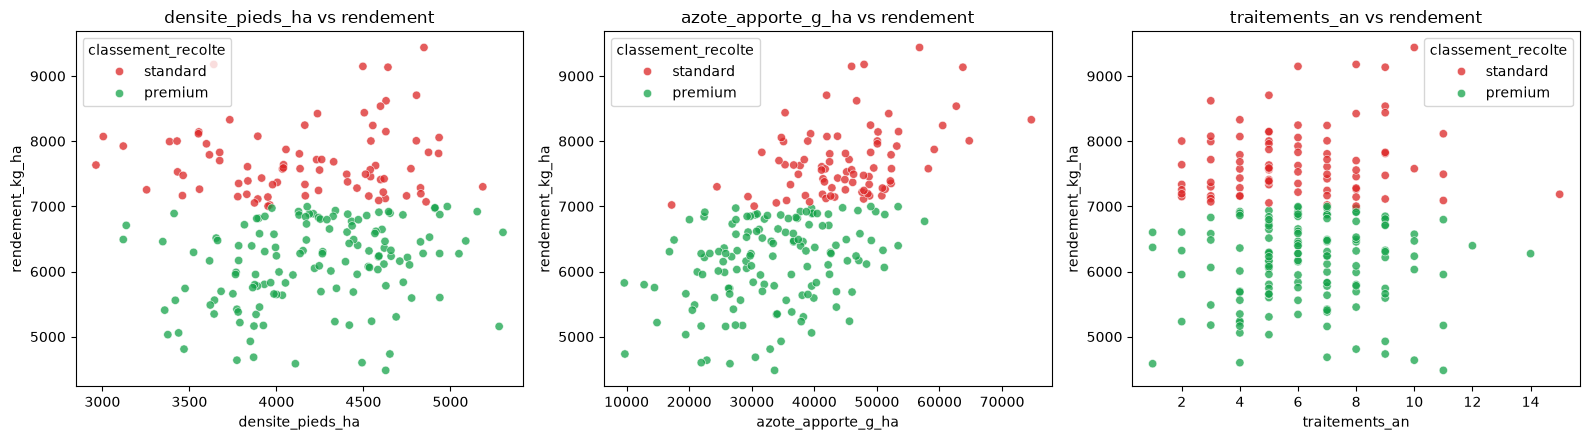

 Part de premium (%) par terroir selon : Azote (g/ha)


tranche_azote,< 25k,25k - 35k,35k - 45k,> 45k
nom_terroir,,,,
Basses plaines sèches,100.0,88.2,44.4,18.8
Coteaux pentus,100.0,93.3,100.0,61.5
Hauts plateaux secs,100.0,94.1,60.0,33.3
Terres humides,75.0,77.8,55.6,9.1


 Part de premium (%) par terroir selon : Densité (pieds/ha)


tranche_densite,< 3800,3800 - 4200,4200 - 4600,> 4600
nom_terroir,,,,
Basses plaines sèches,50.0,50.0,66.7,63.6
Coteaux pentus,83.3,84.6,83.3,80.0
Hauts plateaux secs,60.0,80.0,59.1,68.8
Terres humides,50.0,50.0,64.3,46.2


 Part de premium (%) par terroir selon : Traitements / an


tranche_trait,1 - 4,5 - 6,7 - 8,> 8
nom_terroir,,,,
Basses plaines sèches,47.1,61.1,56.2,75.0
Coteaux pentus,83.3,88.9,90.9,66.7
Hauts plateaux secs,50.0,72.4,76.9,60.0
Terres humides,50.0,50.0,52.9,60.0


In [6]:
print("Rendement min / médiane / max selon le classement")
display(df_q8.groupby("classement_recolte")["rendement_kg_ha"].agg(["count", "min", "median", "max"]).round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, cols_conduite):
    sns.scatterplot(
        data=df_q8, x=col, y="rendement_kg_ha",
        hue="classement_recolte", palette={"premium": "#16a34a", "standard": "#dc2626"},
        alpha=0.75, ax=ax
    )
    ax.set_title(f"{col} vs rendement")
plt.tight_layout()
plt.show()

df_tmp = df_q8.copy()
df_tmp["tranche_azote"] = pd.cut(
    df_tmp["azote_apporte_g_ha"],
    bins=[0, 25000, 35000, 45000, 80000],
    labels=["< 25k", "25k - 35k", "35k - 45k", "> 45k"]
)
df_tmp["tranche_densite"] = pd.cut(
    df_tmp["densite_pieds_ha"],
    bins=[0, 3800, 4200, 4600, 6000],
    labels=["< 3800", "3800 - 4200", "4200 - 4600", "> 4600"]
)
df_tmp["tranche_trait"] = pd.cut(
    df_tmp["traitements_an"],
    bins=[0, 4, 6, 8, 20],
    labels=["1 - 4", "5 - 6", "7 - 8", "> 8"]
)

for col_t, titre in [
    ("tranche_azote", "Azote (g/ha)"),
    ("tranche_densite", "Densité (pieds/ha)"),
    ("tranche_trait", "Traitements / an")
]:
    print(f" Part de premium (%) par terroir selon : {titre}")
    tab = (
        df_tmp.assign(is_prem=df_tmp["classement_recolte"] == "premium")
        .pivot_table(index="nom_terroir", columns=col_t, values="is_prem", aggfunc="mean", observed=False) * 100
    ).round(1)
    display(tab)